# From field-evaporated detector events to atomic geometry


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：aluminium_atom_probe_coordinates

**观测 y：** detector_positions(1, 200000, 2)；standing_voltage(1, 200000)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 按事件顺序的三维原子坐标(nm)。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 球冠离子投影与逐离子原子体积守恒。本地路径为 `solvers.reconstruct闭式角度/累计深度`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 3, 7, 9, 11, 13（cell编号按文件内从0计）。章节包括：# From field-evaporated detector events to atomic geometry；## 2. Data；## 3. Physics；## 4. Method；## 5. Results and scientific comparisons；### Controlled efficiency and image-compression sensitivity；### Independent forward and volume checks；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 无独立原子坐标真值；须强调校准假设。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

This notebook reconstructs the ordered three-dimensional geometry of a **real pure-aluminium OXCART acquisition**. The bound observation is the first 200000 consecutive processed detector events, preserving every detector hit and voltage in that initial window. No species, spatial or target-based selection is applied. The unknown is a continuous atom point cloud, not a fitted single scalar, a voxel image copied from a source, or a mass-spectrum estimate.

The selected inverse is the analytical Geiser branch shipped by the PyCCAPT authors. We compare the alternative Bas branch, independently captured original executions, dimensional consistency, and sensitivity to projection/efficiency assumptions. No independent atomic truth exists. Agreement with the original software establishes numerical extraction fidelity conditional on the stated model, rather than metrological atomic accuracy.

In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
root=Path.cwd()
if not (root/'src').exists():root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.physics_model import project_to_detector,radius_evolution,depth_increments
from src.solvers import reconstruct,bas_reconstruct
from src.visualization import metrics,depth_histogram,point_view
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'figure.dpi':110,'savefig.dpi':180,'axes.spines.top':False,'axes.spines.right':False})
xy,voltage=load_data(root/'data/raw_data.npz')
original_geiser=np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False)['reconstruction'][0]
original_bas=np.load(root/'notebooks/reference_outputs/upstream_bas.npz',allow_pickle=False)['positions_nm']
print('Actual kernel:',sys.executable,'NumPy',np.__version__)
print('Bound real events:',len(xy),'detector units cm, voltage V; original atom-coordinate columns are excluded from inputs.')

Actual kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy 2.4.6
Bound real events: 200000 detector units cm, voltage V; original atom-coordinate columns are excluded from inputs.


## 2. Data

The authors' calibrated event table retains detector positions separately from its previously reconstructed atomic coordinates. Only the detector-position and standing-voltage columns are visible here; the source's old spatial result, mass/charge and species information are neither observations for this inverse nor a route to calibration tuning. The calibrated source file is range-read rather than downloaded wholesale; the selected arrays are independently hashed and reproduced exactly.

The detector view below uses **all events** to form the count-density image, while voltage is plotted in event order. These patterns characterize the observed detector coverage and radius evolution; they are not hidden atomic target information. The effective analysis area follows the explicit author convention $A_D=\pi\max_n(r^D_n)^2$ over this full selected event sequence.

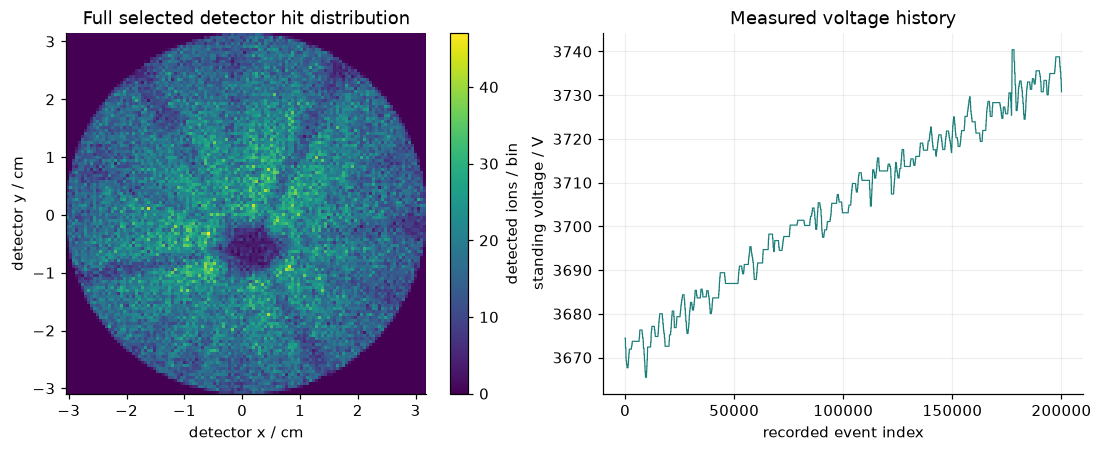

Detector extents / cm: [-3.04653061 -3.0922449 ] [3.18693878 3.14122449] voltage / V: 3665.4899999999925 3740.3999999999955


In [2]:
fig_data,axs=plt.subplots(1,2,figsize=(10.5,4),layout='constrained')
hist,xe,ye=np.histogram2d(xy[:,0],xy[:,1],bins=120)
im=axs[0].imshow(hist.T,origin='lower',extent=[xe[0],xe[-1],ye[0],ye[-1]],cmap='viridis',aspect='equal');fig_data.colorbar(im,ax=axs[0],label='detected ions / bin')
axs[0].set(xlabel='detector x / cm',ylabel='detector y / cm',title='Full selected detector hit distribution')
axs[1].plot(np.arange(len(voltage)),voltage,color='#1b7f79',lw=.8);axs[1].set(xlabel='recorded event index',ylabel='standing voltage / V',title='Measured voltage history');axs[1].grid(alpha=.2)
axs[1].xaxis.set_major_locator(MaxNLocator(5))
plt.show()
print('Detector extents / cm:',np.min(xy,axis=0),np.max(xy,axis=0),'voltage / V:',voltage.min(),voltage.max())

## 3. Physics

Standing voltage $V$ and evaporation field $F$ give specimen radius $R=V/(kF)$, where $k$ is a field factor. Detector radius $r^D$ and flight length $L$ give apparent angle $\theta^p=\arctan(r^D/L)$. Image-compression factor $\xi$ changes that into the specimen launch angle:

$$\theta^a=\theta^p+\arcsin[(\xi-1)\sin\theta^p].$$

With detector azimuth $\phi$, the lateral coordinates are $x=R\sin\theta^a\cos\phi$ and $y=R\sin\theta^a\sin\phi$. The spherical-cap height correction is $R(1-\cos\theta^a)$. Atomic number density $\rho$ and detection efficiency $\eta$ connect each detected ion to removed specimen volume. For analysis area $A_n=A_D/[L/(\xi R_n)]^2$, depth obeys

$$z_n=\sum_{j=0}^{n}\frac{1}{\rho\eta A_j}+R_n(1-\cos\theta^a_n).$$

Here $R$ and reconstructed coordinates are nm, while detector radii and $L$ are mm, so magnification $L/(\xi R)$ is mm/nm and the specimen analysis area is nm². The first ion contributes its own positive volume increment; no fitted depth translation is applied. Parameters are fixed author conventions: $L=110$ mm, $k=4$, $\eta=0.7$, $\xi=1.4$, $F=19$ V/nm and $\rho=60.2$ atoms/nm³. Their uncertainty is examined below rather than adjusted against a hidden atom map.

In [3]:
r=radius_evolution(voltage);increments=depth_increments(xy,voltage)
print('Specimen radius range / nm:',r.min(),r.max())
print('Cumulative removal depth range / nm:',np.cumsum(increments)[0],np.sum(increments))
print('Fixed Al atomic volume / nm³:',1/60.2,'detected-ion inferred volume / nm³:',1/(60.2*.7))

Specimen radius range / nm: 48.23013157894727 49.215789473684154
Cumulative removal depth range / nm: 1.956916416402566e-05 3.8502072206543305
Fixed Al atomic volume / nm³: 0.01661129568106312 detected-ion inferred volume / nm³: 0.023730422401518746


## 4. Method

The cleaned implementation evaluates the projection and atomic-volume equations directly for every event. It retains the source arithmetic order, physical units, angular correction, cap shape and cumulative-depth origin. There is no trained weight, iterative optimizer, hidden initialization or artificially repeated update.

The Bas comparison uses a small-angle magnification and its corresponding spherical-cap correction. The exact checked upstream revision already fixes a historical detector-cm-to-m conversion error in that branch; the cleaned comparison preserves its current correct conversion. These two analytical models can agree near the axis and differ towards the detector edge. Their difference measures model choice, not a known physical reconstruction error.

{
  "Geiser_seconds": 0.020244500003173016,
  "Bas_seconds": 0.010956800004350953,
  "parity": {
    "Geiser fresh vs original": {
      "ncc": 1.0000000000000002,
      "nrmse": 0.0
    },
    "Bas fresh vs original": {
      "ncc": 1.0,
      "nrmse": 0.0
    }
  }
}


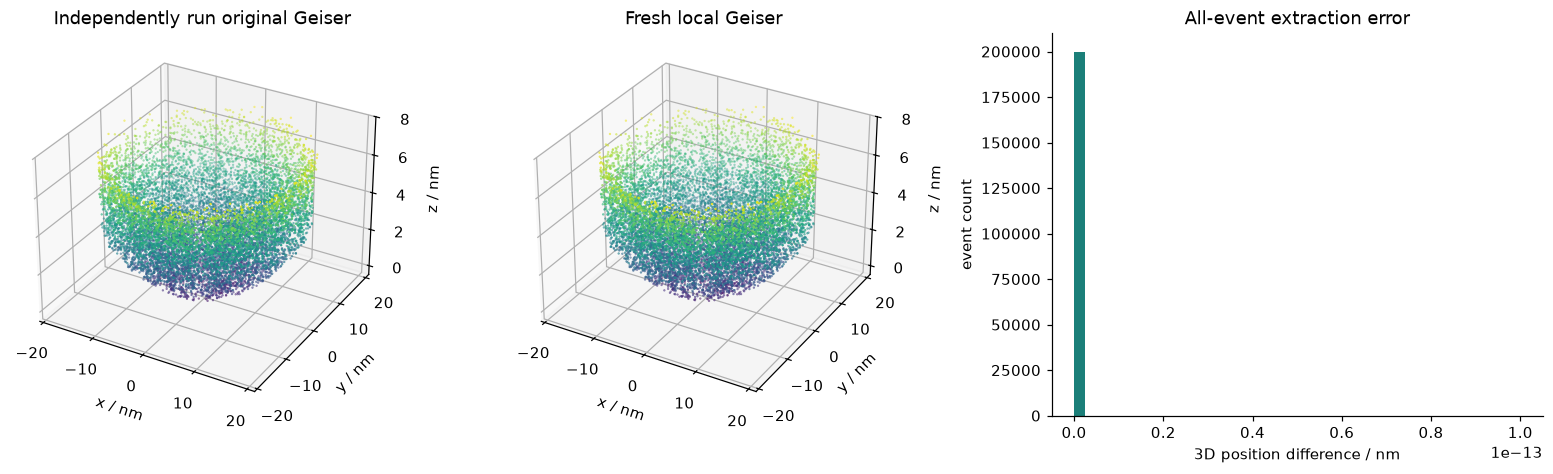

In [4]:
started=time.perf_counter();fresh=reconstruct(xy,voltage);geiser_seconds=time.perf_counter()-started
started=time.perf_counter();fresh_bas=bas_reconstruct(xy,voltage);bas_seconds=time.perf_counter()-started
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh[None])
parity={'Geiser fresh vs original':metrics(fresh,original_geiser),'Bas fresh vs original':metrics(fresh_bas,original_bas)}
print(json.dumps({'Geiser_seconds':geiser_seconds,'Bas_seconds':bas_seconds,'parity':parity},indent=2))
fig_parity=plt.figure(figsize=(14.5,4.2),layout='constrained')
point_view(original_geiser,'Independently run original Geiser',fig_parity.add_subplot(131,projection='3d'))
point_view(fresh,'Fresh local Geiser',fig_parity.add_subplot(132,projection='3d'))
ax=fig_parity.add_subplot(133);err=np.linalg.norm(fresh-original_geiser,axis=1);ax.hist(err,bins=np.linspace(0,max(float(err.max()),1e-13),40),color='#1b7f79');ax.set(xlabel='3D position difference / nm',ylabel='event count',title='All-event extraction error')
plt.show()

## 5. Results and scientific comparisons

The point-cloud panels use deterministic display decimation for rendering only. All coordinate outputs, metrics and count histograms use every one of the 200000 events. The orthogonal density sections below reveal the reconstructed geometry without relying on an occluding 3D viewpoint. Bin counts are display statistics, not a relabelled density truth. A spherical-cap contribution to depth and the cumulative evaporation history should remain visible in interpreting this geometry.

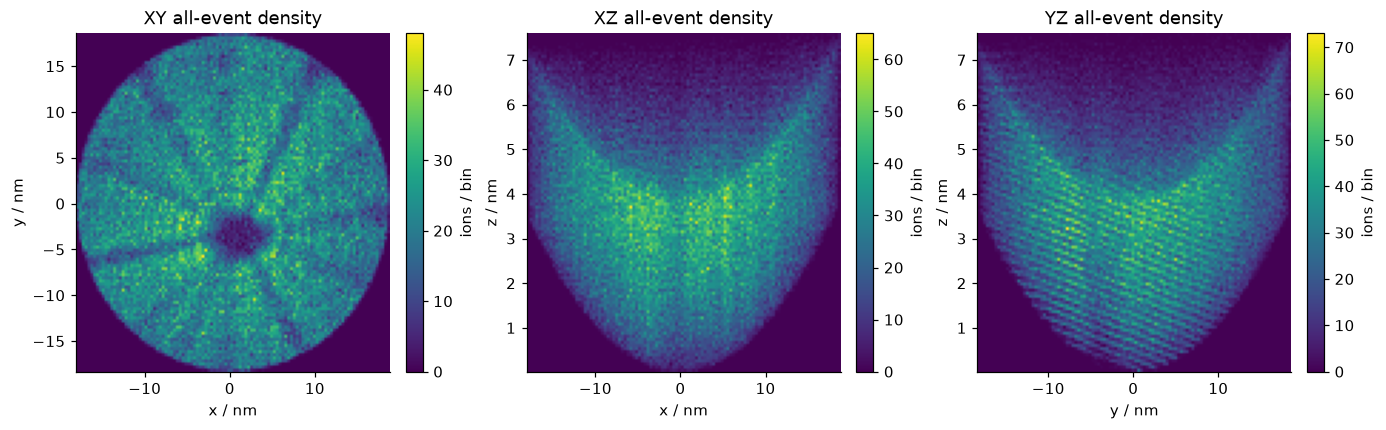

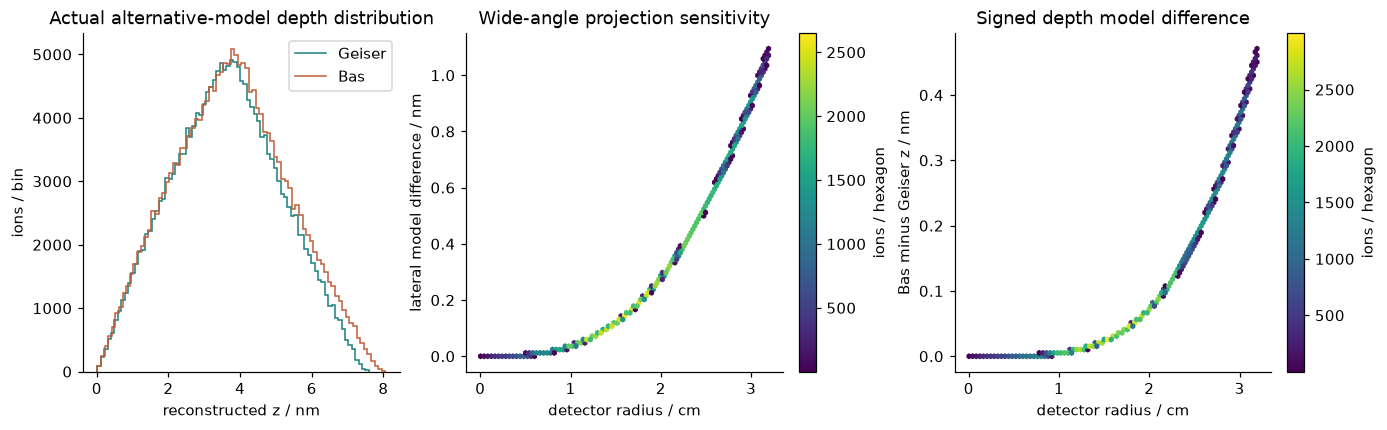

Fresh physical extent / nm: [36.88925138 36.91753135  7.57465345] Bas-Geiser max absolute / nm: [1.08791622 1.04300105 0.47091132]


In [5]:
fig_views,axs=plt.subplots(1,3,figsize=(12.5,3.8),layout='constrained')
for ax,(i,j),name in zip(axs,[(0,1),(0,2),(1,2)],['XY','XZ','YZ']):
 h,e1,e2=np.histogram2d(fresh[:,i],fresh[:,j],bins=110);im=ax.imshow(h.T,origin='lower',extent=[e1[0],e1[-1],e2[0],e2[-1]],cmap='viridis',aspect='auto');ax.set(xlabel='xyz'[i]+' / nm',ylabel='xyz'[j]+' / nm',title=name+' all-event density');fig_views.colorbar(im,ax=ax,label='ions / bin')
plt.show()
fig_models,axs=plt.subplots(1,3,figsize=(12.5,3.8),layout='constrained')
for a,name,color in [(fresh,'Geiser','#1b7f79'),(fresh_bas,'Bas','#c05c38')]:
 counts,edges=depth_histogram(a);axs[0].stairs(counts,edges,label=name,color=color)
axs[0].set(xlabel='reconstructed z / nm',ylabel='ions / bin',title='Actual alternative-model depth distribution');axs[0].legend()
radial=np.linalg.norm(xy,axis=1);difference=fresh_bas-fresh
im1=axs[1].hexbin(radial,np.linalg.norm(difference[:,:2],axis=1),gridsize=80,mincnt=1,cmap='viridis');fig_models.colorbar(im1,ax=axs[1],label='ions / hexagon');axs[1].set(xlabel='detector radius / cm',ylabel='lateral model difference / nm',title='Wide-angle projection sensitivity')
im2=axs[2].hexbin(radial,difference[:,2],gridsize=80,mincnt=1,cmap='viridis');fig_models.colorbar(im2,ax=axs[2],label='ions / hexagon');axs[2].set(xlabel='detector radius / cm',ylabel='Bas minus Geiser z / nm',title='Signed depth model difference')
plt.show()
print('Fresh physical extent / nm:',np.ptp(fresh,axis=0),'Bas-Geiser max absolute / nm:',np.max(np.abs(difference),axis=0))

### Controlled efficiency and image-compression sensitivity

Changing efficiency alters the inferred removed volume while retaining the measured hit geometry. Changing image compression alters lateral projection and the specimen analysis area. The following six full reconstructions vary one assumption at a time on the exact same input; none uses a cached result or changes the observed detector events. The reference parameters remain fixed for submission. These curves quantify calibration sensitivity, not a fitted estimate of the true instrument parameters.

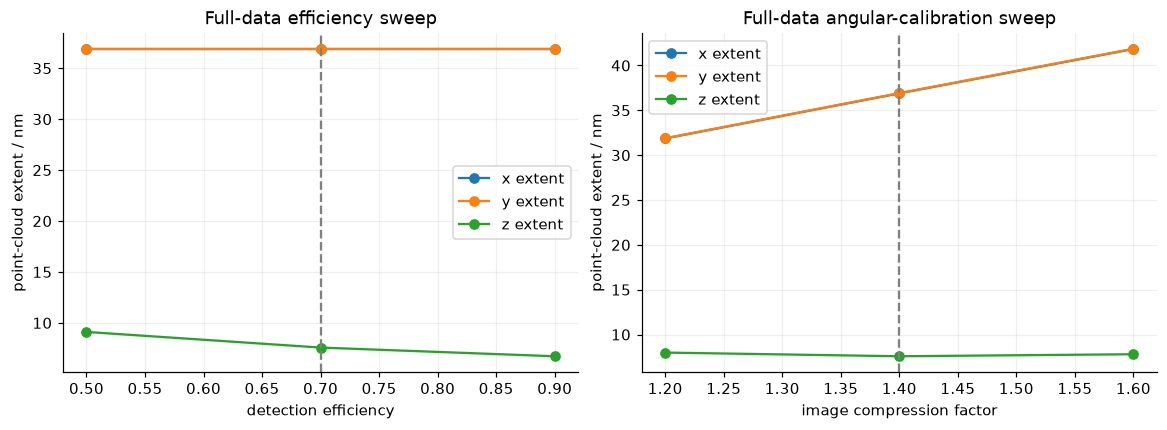

In [6]:
efficiencies=np.array([.5,.7,.9]);compressions=np.array([1.2,1.4,1.6])
eff_results=[reconstruct(xy,voltage,det_eff=float(e)) for e in efficiencies]
icf_results=[reconstruct(xy,voltage,icf=float(c)) for c in compressions]
eff_extents=np.array([np.ptp(a,axis=0) for a in eff_results]);icf_extents=np.array([np.ptp(a,axis=0) for a in icf_results])
fig_sensitivity,axs=plt.subplots(1,2,figsize=(10.5,3.8),layout='constrained')
for i,label in enumerate(['x extent','y extent','z extent']):
 axs[0].plot(efficiencies,eff_extents[:,i],'o-',label=label);axs[1].plot(compressions,icf_extents[:,i],'o-',label=label)
axs[0].set(xlabel='detection efficiency',ylabel='point-cloud extent / nm',title='Full-data efficiency sweep');axs[0].axvline(.7,color='gray',ls='--')
axs[1].set(xlabel='image compression factor',ylabel='point-cloud extent / nm',title='Full-data angular-calibration sweep');axs[1].axvline(1.4,color='gray',ls='--')
for ax in axs:ax.legend();ax.grid(alpha=.2)
plt.show()

### Independent forward and volume checks

The corrected-angle equation can be inverted independently:

$$\tan\theta^p=\frac{\sin\theta^a}{\cos\theta^a+\xi-1}.$$

Using this identity to project the reconstructed lateral coordinates back to detector centimetres tests the angle and unit conventions without repeating the inverse's atan-plus-asin sequence. The depth-volume check sums $A_n\Delta z_n$ and compares it to $N/(\rho\eta)$ for $N$ detected ions. These checks are necessary physical consistency checks; they do not establish unique original atomic positions in the presence of trajectory and calibration errors.

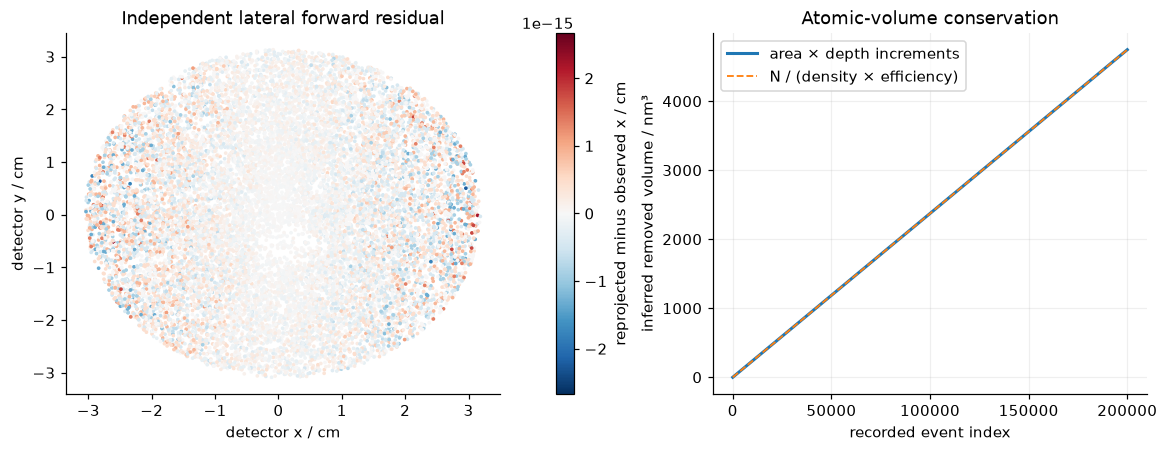

Maximum independent reprojection residual / cm: 2.6645352591003757e-15
Total area×depth / nm³: 4746.084480303749 independent ion-volume / nm³: 4746.084480303749


In [7]:
projected=project_to_detector(fresh,voltage);residual=projected-xy
det_area=np.pi*np.max(np.linalg.norm(xy*10,axis=1))**2
spec_area=det_area/(110/(1.4*r))**2
volume_step=spec_area*increments;expected=np.arange(1,len(xy)+1)/(60.2*.7)
fig_physics,axs=plt.subplots(1,2,figsize=(10.5,4),layout='constrained')
sample=np.arange(0,len(xy),max(1,len(xy)//15000));lim=max(float(np.max(abs(residual))),1e-15)
im=axs[0].scatter(xy[sample,0],xy[sample,1],c=residual[sample,0],cmap='RdBu_r',vmin=-lim,vmax=lim,s=2,rasterized=True);fig_physics.colorbar(im,ax=axs[0],label='reprojected minus observed x / cm');axs[0].set(xlabel='detector x / cm',ylabel='detector y / cm',title='Independent lateral forward residual')
axs[1].plot(np.arange(len(xy)),np.cumsum(volume_step),label='area × depth increments',lw=2);axs[1].plot(np.arange(len(xy)),expected,'--',label='N / (density × efficiency)',lw=1.2);axs[1].set(xlabel='recorded event index',ylabel='inferred removed volume / nm³',title='Atomic-volume conservation');axs[1].legend();axs[1].grid(alpha=.2);axs[1].xaxis.set_major_locator(MaxNLocator(5))
plt.show()
print('Maximum independent reprojection residual / cm:',np.max(abs(residual)))
print('Total area×depth / nm³:',volume_step.sum(),'independent ion-volume / nm³:',len(xy)/(60.2*.7))

## 6. Conclusion

The fresh cleaned code reconstructs the entire bound real event sequence and reproduces the original Geiser and Bas coordinates under fixed author instrument/material conventions. Independent detector reprojection and atomic-volume conservation validate the angular, unit and depth-normalization mathematics. Orthogonal density views, alternative projection maps and controlled efficiency/compression sweeps show the scientific consequences of the assumptions.

The result is a model-dependent atomic geometry. No independent atom-position truth, crystallographic calibration or absolute metrological accuracy is invented. The observation prefix does not describe the full analysed specimen. Detector losses, trajectory aberrations, analysis-area conventions and calibration uncertainty remain limits. All fresh results here were actually computed; archived original arrays are used solely for identified reproducibility comparisons.

In [8]:
import importlib.util
spec=importlib.util.spec_from_file_location('standalone_apt_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,status=judge.evaluate(root/'output/reconstruction.npz');assert status==0;print(json.dumps(report,indent=2))
private=os.environ.get('IMAGING101_APT_EXPORT')
if private:
 export=Path(private);export.mkdir(parents=True,exist_ok=True)
 for i,fig in enumerate([fig_data,fig_parity,fig_views,fig_models,fig_sensitivity,fig_physics],1):
  for ext in ['png','svg','pdf']:fig.savefig(export/f'apt-{i}.{ext}',bbox_inches='tight')
 np.savez_compressed(export.parent/'apt_experiments.npz',fresh_geiser=fresh,fresh_bas=fresh_bas,efficiencies=efficiencies,efficiency_extents_nm=eff_extents,compressions=compressions,compression_extents_nm=icf_extents,forward_residual_cm=residual,volume_step_nm3=volume_step)
 summary={'parity':parity,'Geiser_seconds':geiser_seconds,'Bas_seconds':bas_seconds,'reprojection_max_cm':float(np.max(abs(residual))),'volume_nm3':float(volume_step.sum()),'expected_volume_nm3':len(xy)/(60.2*.7),'judge':report,'actual_kernel':sys.executable,'numpy':np.__version__}
 (export.parent/'apt_experiments.json').write_text(json.dumps(summary,indent=2),encoding='utf8')
plt.close('all')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0000000000000002,
    "nrmse": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-10
    }
  },
  "errors": []
}
